<a href="https://colab.research.google.com/github/Rox-0864/Proyecto-de-Predicci-n-de-Churn-en-Telecomunicaciones---Grupo-3/blob/main/Proyecto_Churn_Telecomunicaciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Análisis de Situación.**

Una empresa de Telecomunicaciones quiere establecer estrategias de retención de clientes. Para conseguirlo, se aplica un proceso de análisis de datos y machine learning para entender el comportamiento de los clientes y descubrir aquellos patrones o características que repercutan en que un cliente decida dejar a la empresa.

Se tiene una base de datos con información demográfica del cliente e información del servicio del cliente. También se tiene una variable objetivo que identifica a los clientes que se fueron y los que no.

# **Preparación del entorno y carga de datos**

In [1]:
#Carga de librerias para el desarrollo del proyecto
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
from sklearn import metrics
from sklearn.metrics import roc_curve
from sklearn.metrics import recall_score, confusion_matrix, precision_score, f1_score, accuracy_score, classification_report, roc_curve, roc_auc_score

In [2]:
# Extraigo los datos de la fuente de origen

import kagglehub

# se obtiene los datos utilizando la api de Kaggle
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path) # Observo la ruta donde se guarda el archivo

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [3]:
# Cargo base de datos
datos = pd.read_csv("/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
datos.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **Vistazo general de los datos**

In [4]:
#observo la información general de los datos
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


* La base de datos tiene una estructura de 7043 filas y 21 columns
* No se observa la existencia de valores nulos
* Existe un error en el tipo de dato de la columna *TotalCharges*. Esta contiene registros numéricos; sin embargo, esta asignada como tipo de dato object

In [5]:
#verifico si existen registros duplicados
print('la cantidad de valores duplicados es:', datos.duplicated().sum())

la cantidad de valores duplicados es: 0


In [6]:
# analizo cuantos valores únicos posee cada columna
datos.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


# **Limpieza y Preparación de datos**

In [7]:
#convierto a numérico a la columna TotalCharges
datos['TotalCharges'] = pd.to_numeric(datos['TotalCharges'], errors='coerce')

In [8]:
#valido la conversión
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


El cambio del tipo de dato se aplicó correctamente.

También se observa presencia de valores nulos en la columna Total Charges

In [9]:
#cuento los valores nulos existentes.
datos.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [10]:
#analizo los registros en donde estan los valores nulos
datos[datos['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Se observa la particularidad de que en todos los registros en los que hay los valores nulos, la columna *tenure* tiene el valor 0.

In [11]:
#Verifico cuantos registros hay en los que la columna tenure es 0. Esto con el fin de observar si hay alguna referencia que me oriente a realizar alguna imputación en los nulos.
datos[datos['tenure'] == 0].shape

(11, 21)

Se observa que en todos los registros en donde la columna *tenure* es 0 existen los valores nulos en la columna *TotalCharge*

Esto tiene lógica. Considerando que la columna *tenure* indica el número de meses que el cliente lleva en la empresa, un valor de 0 representa que el cliente aún no ha cumplido el mes de servicio, por lo que aun no existe un importe o factura cargada al cliente.

En este caso, **se considera eliminar las columnas en donde existen valores nulos**, debido a que estos representan ménos del 0,5% del total de los datos y retirarlos no afectaría al desarrollo del proyecto. Además considerar opciones como imputarlo con considerando estadísticos descriptivos como la media o media no sería adecuado dada la particularidad de la columna por su dependencia explicita de la columna *tenure*

In [12]:
#elimino los registros en donde existen los valores nulos
datos.dropna(inplace=True)
datos.reset_index(drop=True, inplace=True) #reseteo los índices de los registros.

In [13]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


In [14]:
# Elimino la columna CustomerID. Esta no aporta al desarrollo del modelo
datos.drop('customerID', axis=1, inplace=True)
datos.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **Análisis Exploratorio de los Datos**

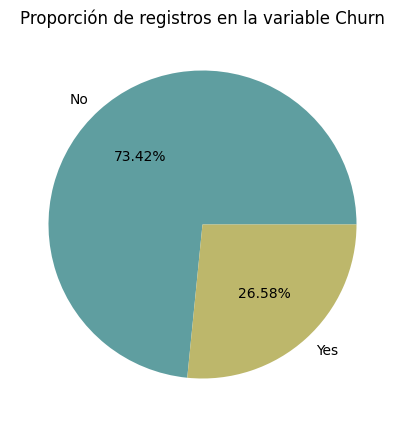

In [15]:
#observa la proporción de clientes que se han retirado y los que se mantienen
plt.figure(figsize=(10,5))
plt.pie(datos['Churn'].value_counts(), labels=datos['Churn'].value_counts().index, autopct='%1.2f%%', colors=['#5F9EA0','#BDB76B'])
plt.title('Proporción de registros en la variable Churn')
plt.show()

La base de datos cuenta con una mayor proporción de clientes que permanecen (73,42%)

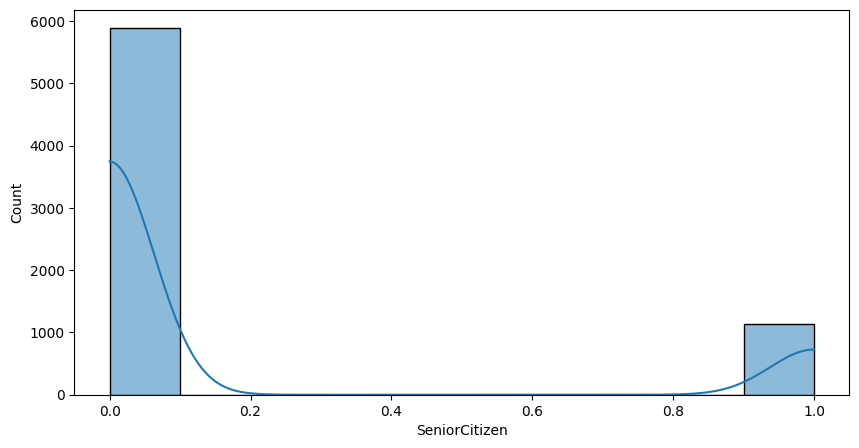

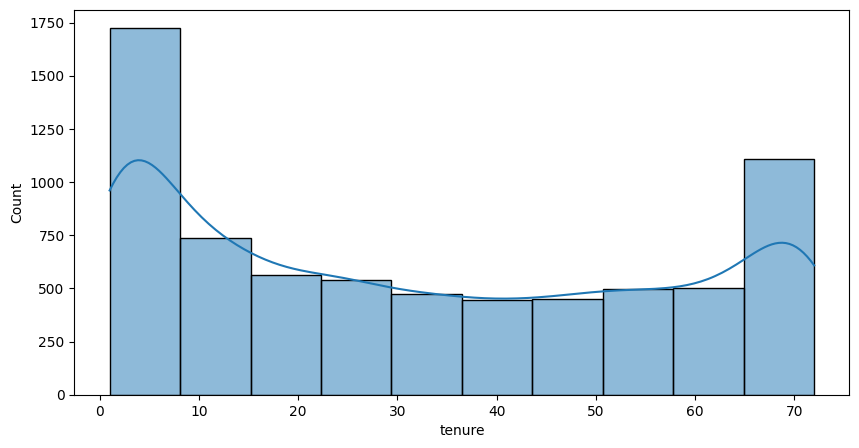

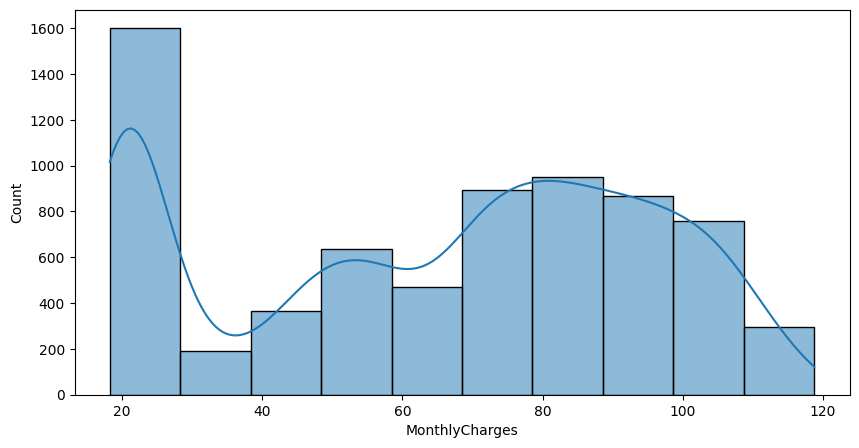

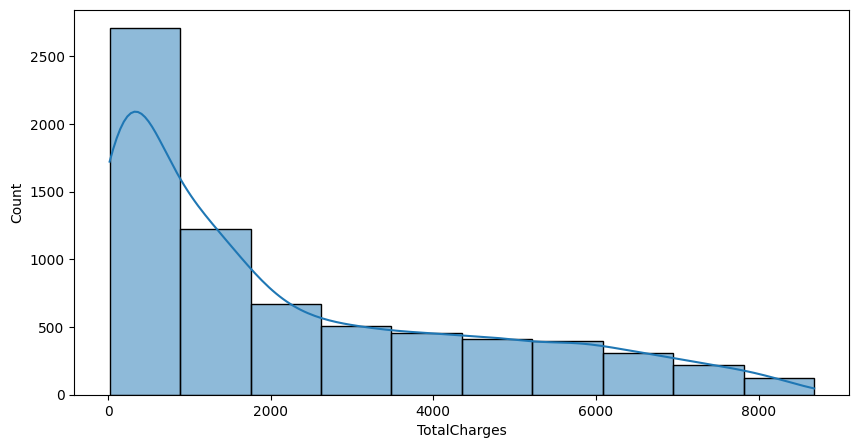

In [16]:
# analizo la distribución de datos en las variables cuantitativas
for i in datos.select_dtypes(include=['int64', 'float64']):
  plt.figure(figsize=(10,5))
  sns.histplot(data=datos[i], bins=10, kde=True)

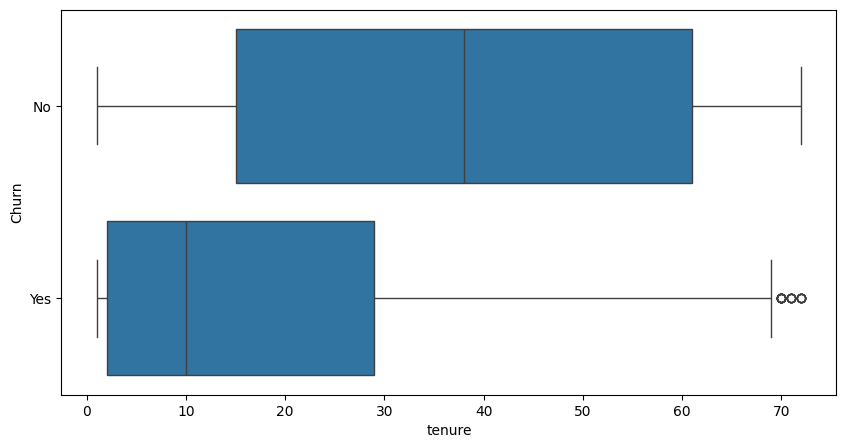

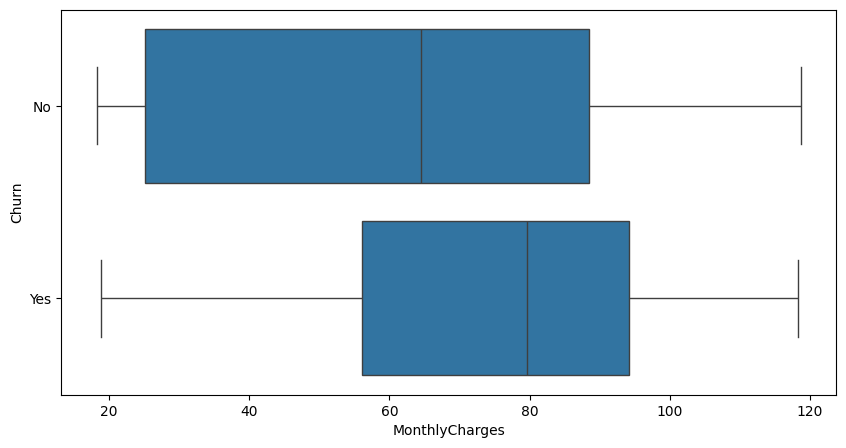

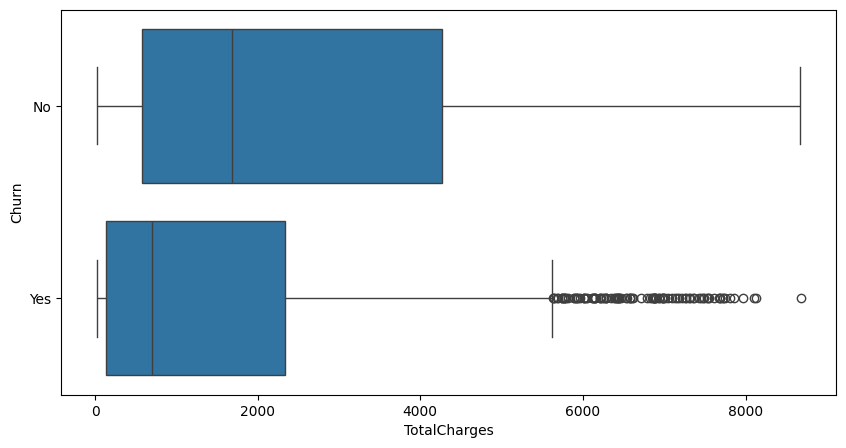

In [17]:
datos_cuantitativos = datos.select_dtypes(include=['int64', 'float64']).drop('SeniorCitizen', axis=1)
for i in datos_cuantitativos.columns:
  plt.figure(figsize=(10,5))
  sns.boxplot(x=datos[i], y=datos['Churn'])

Estos son algunos aspectos relevantes que se observa con el gráfico de caja y bigote:

* La mayoria de clientes que desertaron tienen poco tiempo haciendo uso de los servicios de la empresa. Estos mayoritariamente se distribuyen entre los 3 y 30 meses de servicio.

* El valor que pagan mensualmente los clientes parece ser también un aspecto relevante. De los clientes que desertaron, la mayor parte se concentraba en valores altos de pagos mensuales, en comparación a los clientes que desertaron.



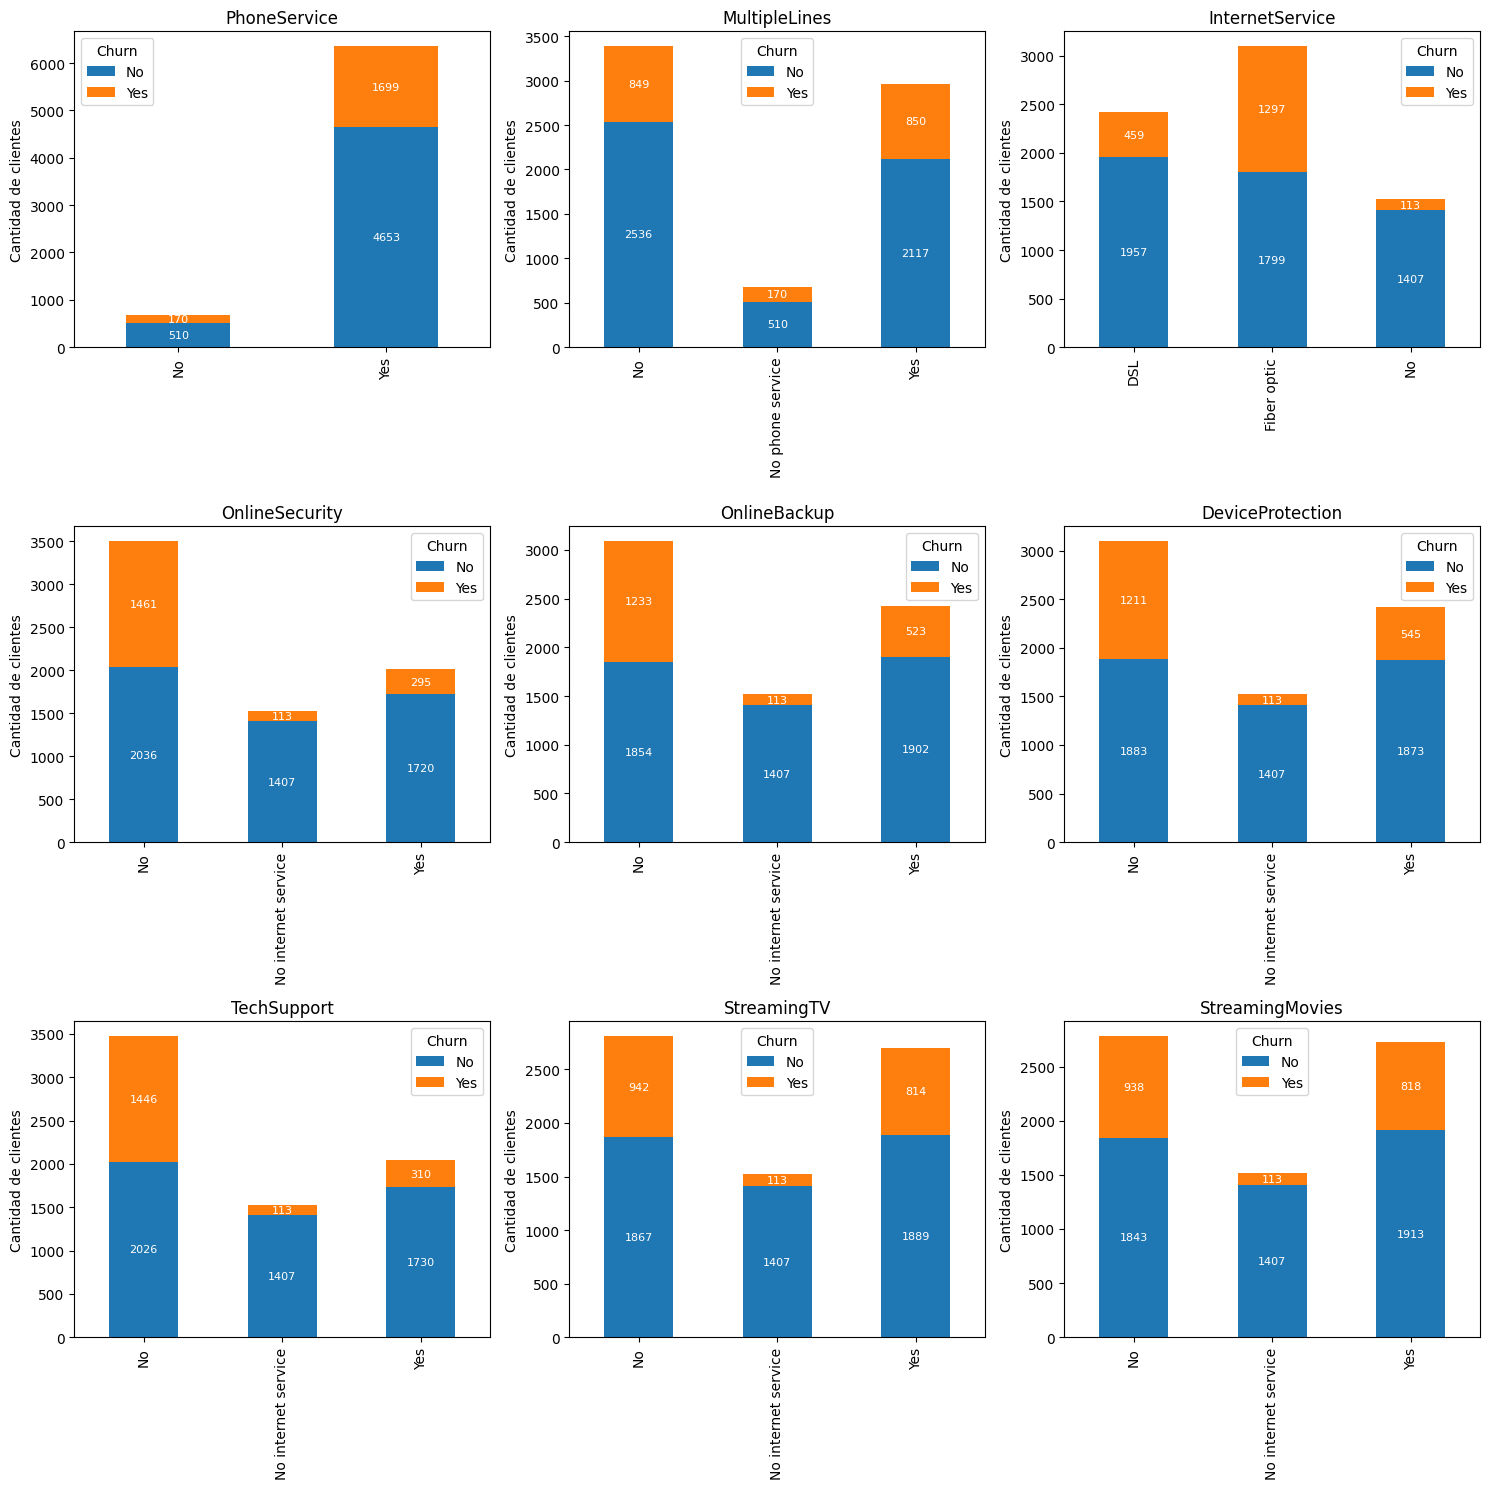

In [18]:
servicios = ['PhoneService','MultipleLines','InternetService','OnlineSecurity',
           'OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, item in enumerate(servicios):
    #colors = plt.cm.tab10.colors  # paleta con varios colores
    ax = axes[i // 3, i % 3]
    # Crear tabla cruzada: filas = categorías del servicio, columnas = Churn
    tabla = pd.crosstab(datos[item], datos['Churn'])

    # Graficar como barras apiladas
    barras = tabla.plot(kind='bar', stacked=True, ax=ax, color=plt.cm.tab10.colors)

    for container in barras.containers:
        barras.bar_label(container, label_type='center', fontsize=8, color="white")

    ax.set_title(item)
    ax.set_xlabel("")  # opcional: quitar etiqueta en x
    ax.set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

Estos son aspectos relevantes que se pueden observar:

* Existe una alta tasa de deserción cuando los clientes no utilizan servicios técnicos adicionales que pueden ofrecer un mejor servicio general, como lo son: seguridad online, copia de seguridad en línea, protección del dispositivo y soporte técnico.

* Tener servicio de tv y de películas parece no ser relevante, puesto que la tasa de clientes que desertaron es similar para aquellos que poseen estos servicios como para los que no.

* Hay una alta tasa de deserción de aquellos clientes que tuvieron internet por fibra óptica. Esto novedoso, dado que el servicio por fibra permite mayores capacidades y en general suele ser una tecnología más eficiente.

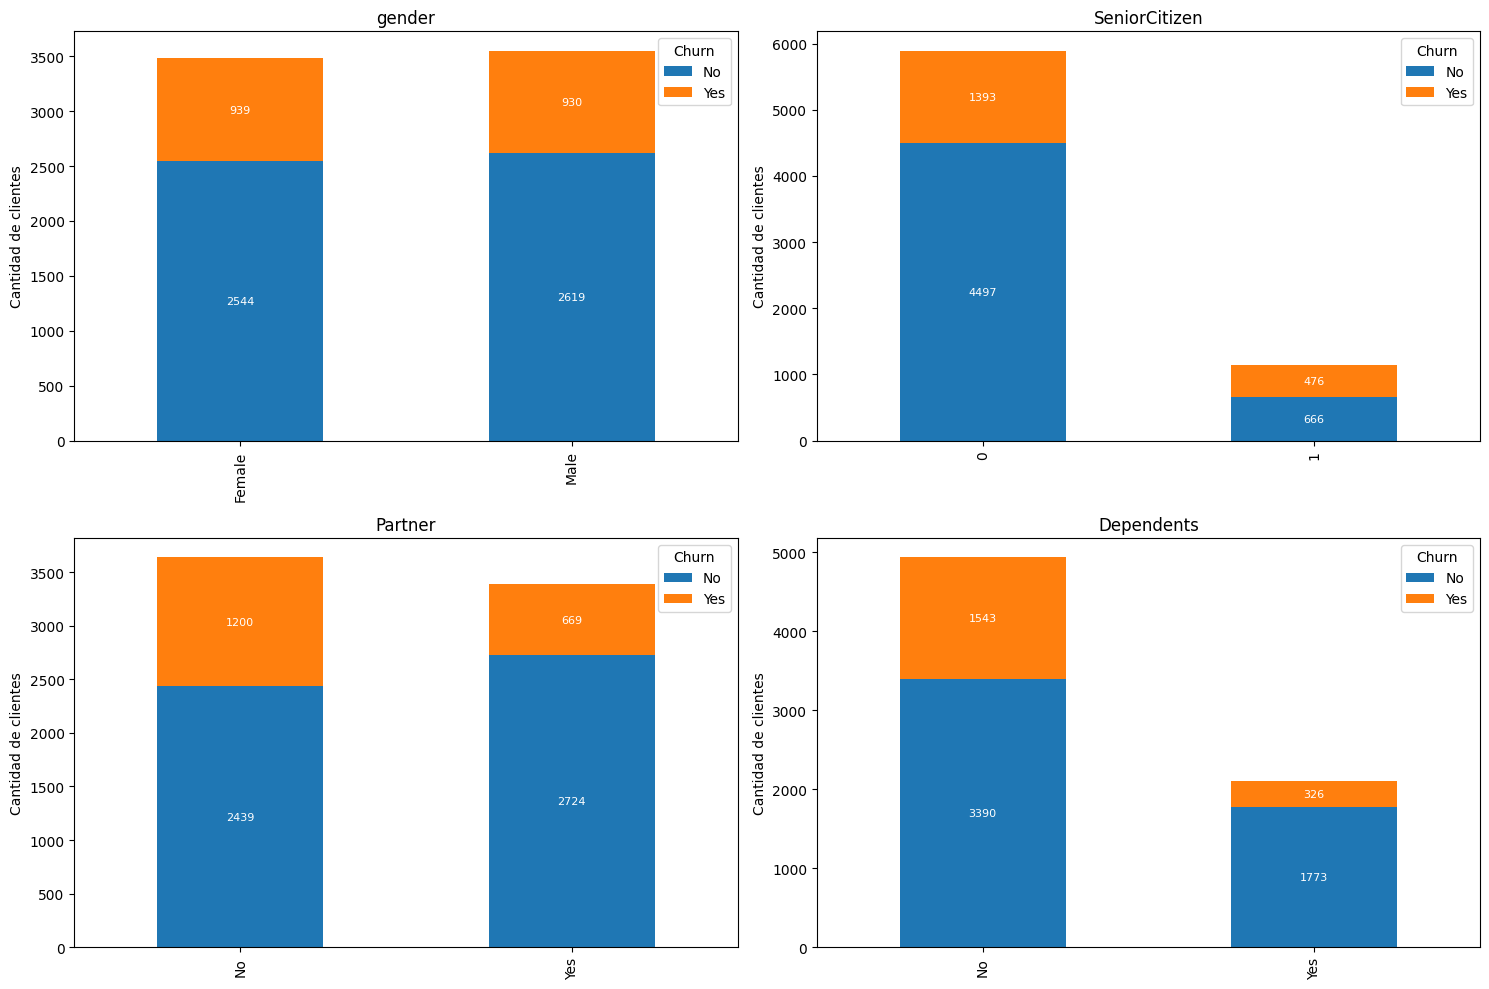

In [19]:
demograf = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for i, item in enumerate(demograf):
    ax = axes[i//2, i%2]

    tabla = pd.crosstab(datos[item], datos['Churn'])

    # Graficar
    barras = tabla.plot(
        kind='bar', stacked=True, ax=ax, color=plt.cm.tab10.colors
    )

    # Añadir etiquetas dentro de cada barra
    for container in barras.containers:
        barras.bar_label(container, label_type='center', fontsize=8, color="white")

    ax.set_title(item)
    ax.set_xlabel("")
    ax.set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

Se observa una mayor deserción en aquellos clientes que no tienen compañeros/pareja y también aquelos que no tienen dependientes.

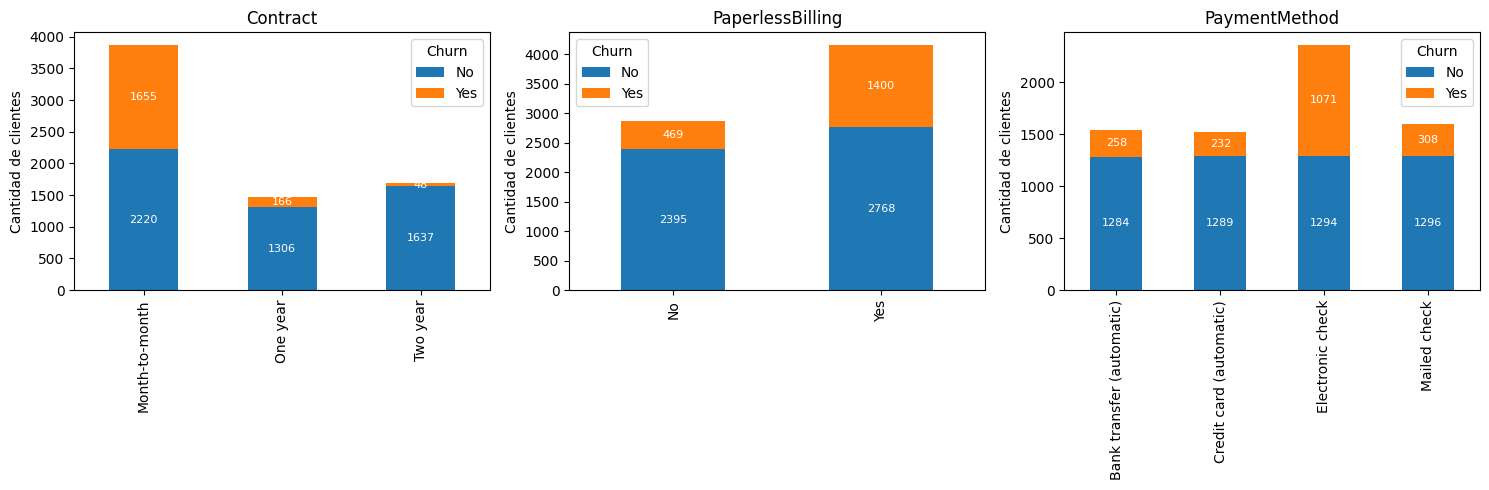

In [20]:
terminos = ['Contract', 'PaperlessBilling', 'PaymentMethod']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, item in enumerate(terminos):
    ax = axes[i]

    tabla = pd.crosstab(datos[item], datos['Churn'])

    barras = tabla.plot(
        kind='bar', stacked=True, ax=ax, color=plt.cm.tab10.colors
    )
    for container in barras.containers:
        barras.bar_label(container, label_type='center', fontsize=8, color="white")

    ax.set_title(item)
    ax.set_xlabel("")
    ax.set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

* Se observa que aquellos clientes que tienen un contrato de pago mes a mes son mas propensos a desertar, en comparación a los otros tipos de contrato.

* Los clientes que reciben facturación electrónica también son más propensos a ir.

* Aquellos clientes que pagan mediante cheque electrónico presentan una mayor cantidad de desertores.

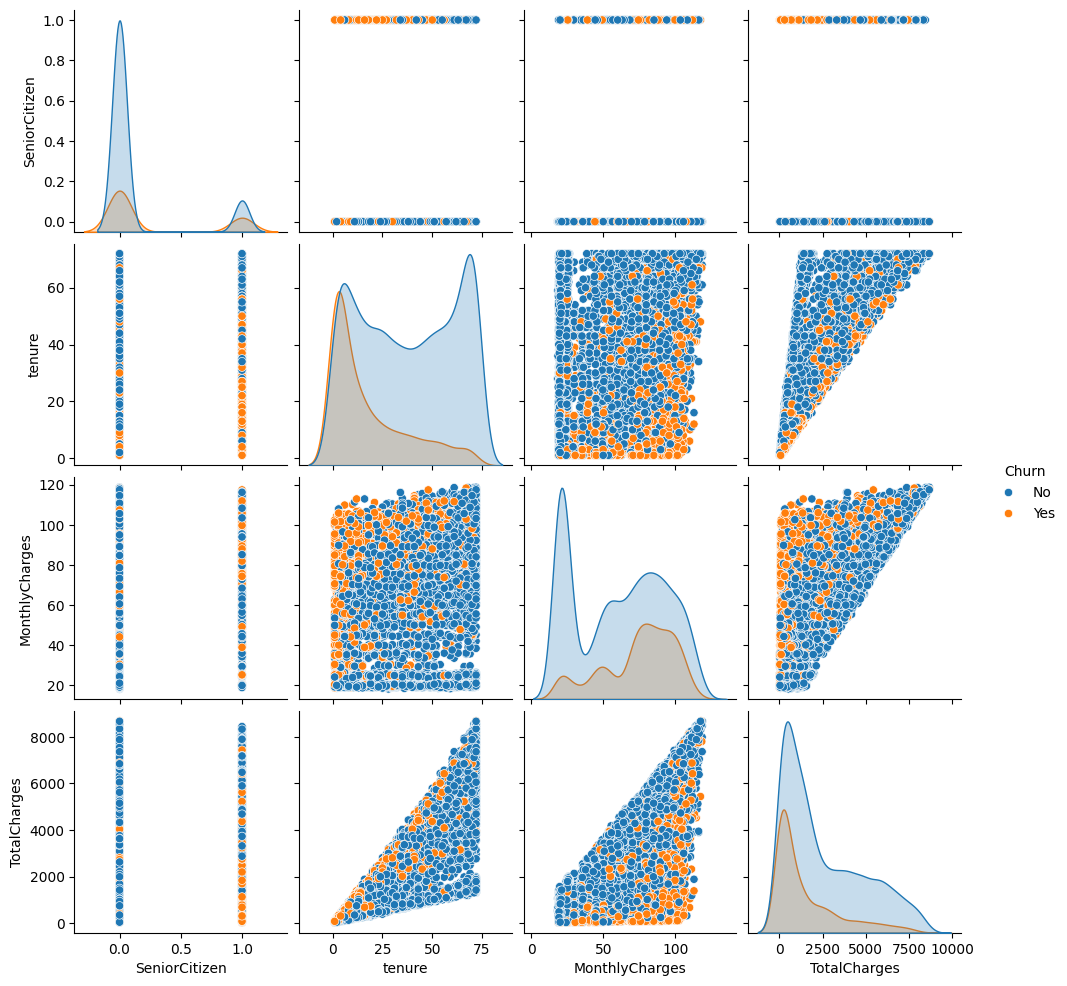

In [21]:
sns.pairplot(datos, hue='Churn')

* Se observa que los clientes que se han retirado son en su mayoria clientes que llevan poco tiempo con el servicio de la empresa y que pagan valores más altos mensualmente.

* Clientes que son adultos mayores y con poco tiempo de servicio parecen ser más propensos a retirarse.

## **Preprocesamiento de los Datos**

Se adapta las variables para que puedan ser utilizadas en el modelo.

In [22]:
datos_final = datos.copy() # copio el dataset en una nueva variable sobre la cual voy a aplicar el preprocesamiento.

In [23]:
#Elimino la variable de Género. No tiene relevancia.
datos_final.drop('gender', axis=1, inplace=True)

In [24]:
# Genero variables dummies de las variables cualitativas que poseen más de dos categorias
datos_final = pd.get_dummies(datos_final, columns=[ 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'], dtype=float)

In [25]:
datos_final.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,Yes,No,1,No,Yes,29.85,29.85,No,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0,No,No,34,Yes,No,56.95,1889.50,No,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,No,No,2,Yes,Yes,53.85,108.15,Yes,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0,No,No,45,No,No,42.30,1840.75,No,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0,No,No,2,Yes,Yes,70.70,151.65,Yes,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [26]:
datos_final.columns

Index(['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'MultipleLines_No', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'InternetService_DSL',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No',
       'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit c

In [27]:
#Elimino columnas que son repetitivas luego de generar las variables dummies. Al decir repetitivas me refiero a que basicamente es una misma columna que se repite con otro nombre.
datos_final.drop(columns=['MultipleLines_No','MultipleLines_No phone service','OnlineSecurity_No internet service','OnlineBackup_No internet service','DeviceProtection_No internet service','TechSupport_No internet service','StreamingTV_No internet service','StreamingMovies_No internet service'], inplace=True)

In [28]:
datos_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 32 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   SeniorCitizen                            7032 non-null   int64  
 1   Partner                                  7032 non-null   object 
 2   Dependents                               7032 non-null   object 
 3   tenure                                   7032 non-null   int64  
 4   PhoneService                             7032 non-null   object 
 5   PaperlessBilling                         7032 non-null   object 
 6   MonthlyCharges                           7032 non-null   float64
 7   TotalCharges                             7032 non-null   float64
 8   Churn                                    7032 non-null   object 
 9   MultipleLines_Yes                        7032 non-null   float64
 10  InternetService_DSL                      7032 no

In [29]:
#categorizo las variables binarias que aún son cualitativas.
datos_final.replace({'Yes': 1, 'No': 0}, inplace=True)

/tmp/ipython-input-2643301887.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  datos_final.replace({'Yes': 1, 'No': 0}, inplace=True)


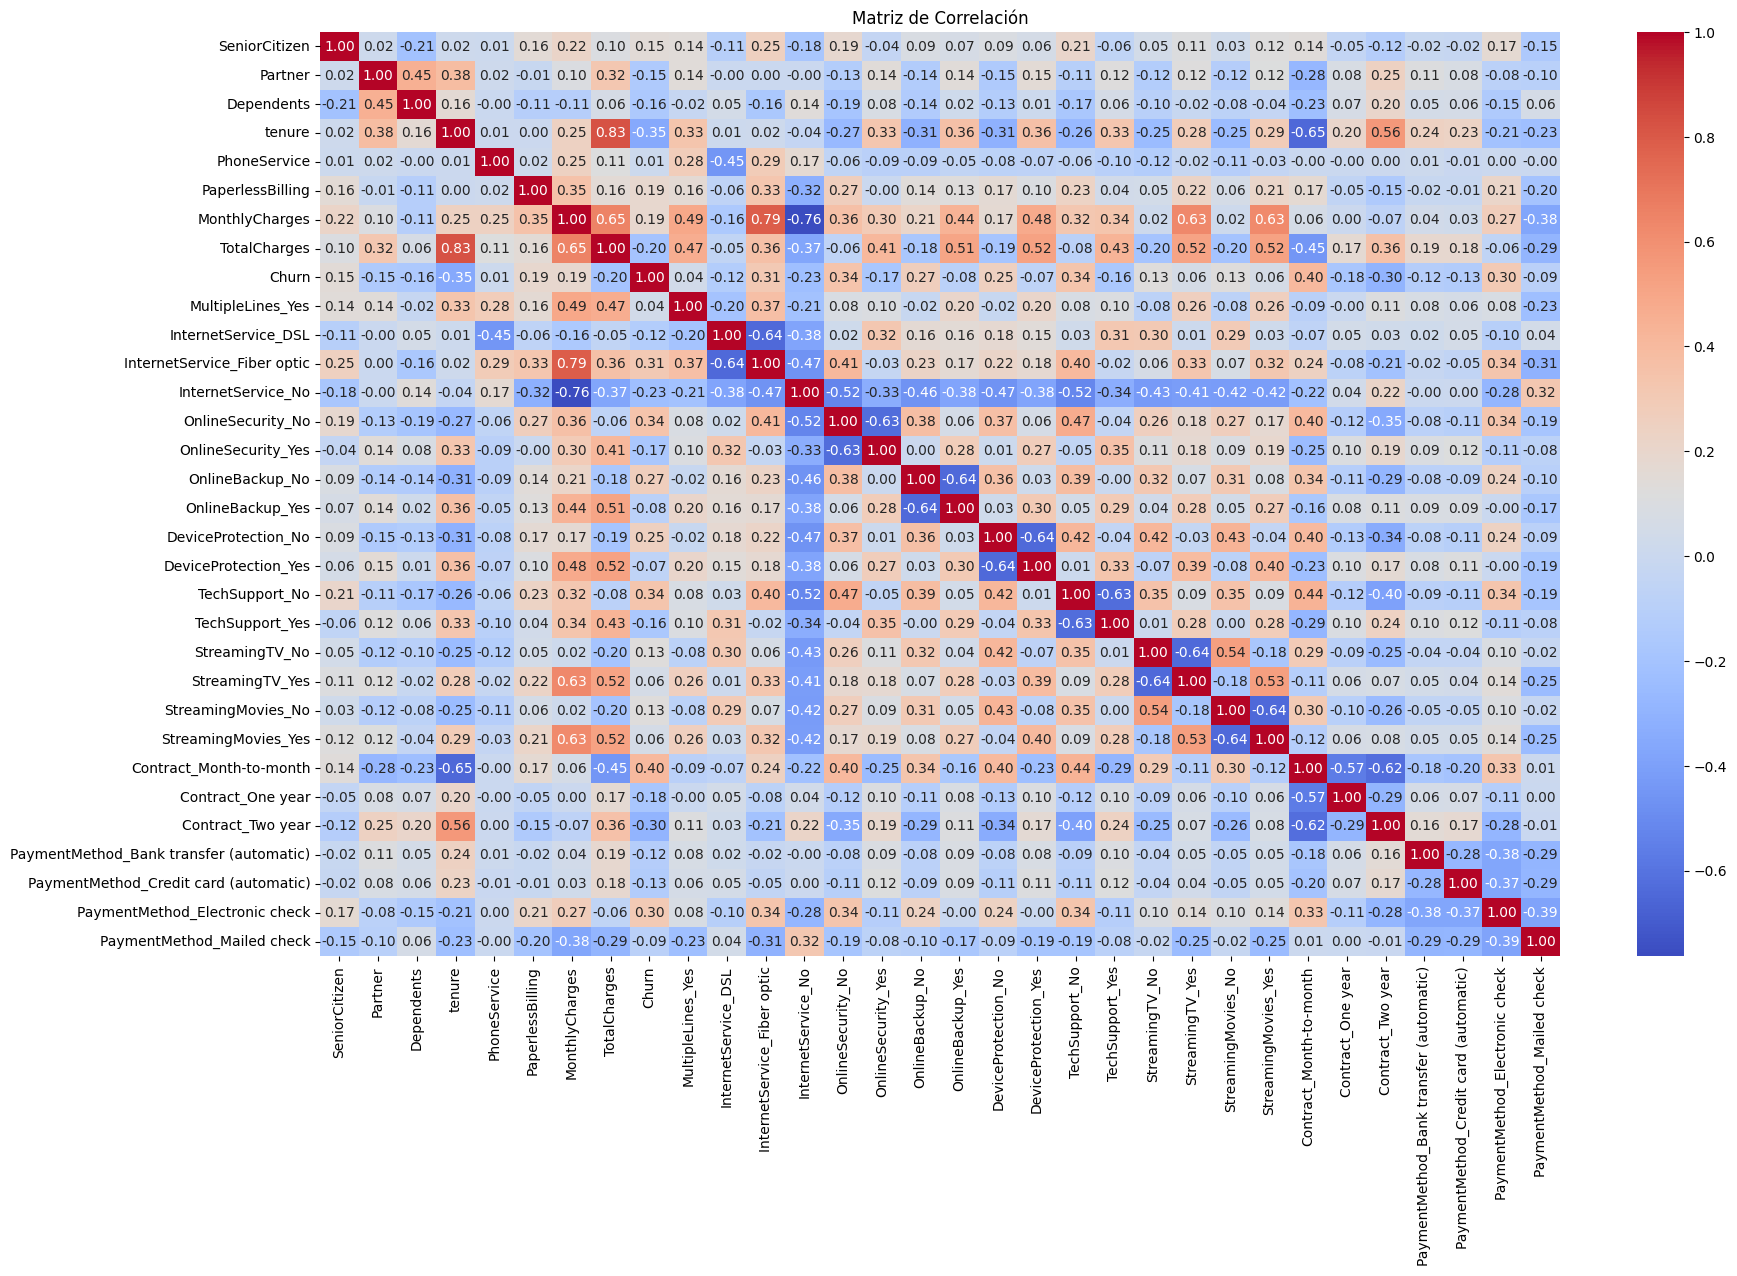

In [30]:
correlacion = datos_final.corr()

plt.figure(figsize=(20, 12))
sns.heatmap(correlacion, annot=True, fmt ='.2f',cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [31]:
#elimino otros variables que parecen ser repetitivas y que pueden generar multicolinealidad
datos_final.drop(columns=['OnlineSecurity_No','OnlineBackup_No','DeviceProtection_No','TechSupport_No','StreamingTV_No','StreamingMovies_No'], inplace=True)

<Axes: >

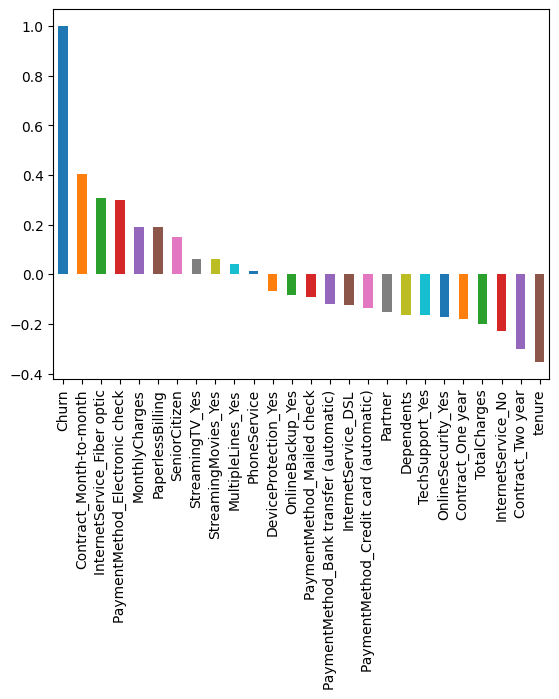

In [33]:
#visualizo la correlación de las variables con mi variable objetivo Churn
datos_final.corr()['Churn'].sort_values(ascending = False).plot(kind='bar', color=plt.cm.tab10.colors)

* Se puede observa de una forma visual más clara la correlación de las variables con la variable objetivo, ya sea de forma positiva o negativa. Por ejemplo, la variable de tipo de contrato mes a mes es la que mayor correlación positiva tiene, esto implica que cuando el cliente tiene este tipo de contrato (valor 1) existe mayor probabilidad de deserción. En el caso opuesto la variable de tiempo de permanencia (ternure), representa que cuando menor es el tiempo de permanencia, mayor es la probabilidad de deserción (Churn = 1).

* Por otro lado variables relacionadas al servicio de teléfono son las que menor relación directa tienen con la variable objetivo.

## **Modelado**

In [34]:
#divido los datos
X = datos_final.drop('Churn', axis=1)
y = datos_final['Churn']

In [35]:
#divido los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### **Modelo de Regresión Logística**

In [36]:
scaler = StandardScaler() #creo un objeto escalador
scaler.fit(X_train) # aprendo los parámetros de escalado a partir del conjunto de entrenamiento
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [42]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)


In [43]:
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [44]:
X_train_scaled.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_Yes,InternetService_DSL,...,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-0.43759,-0.962481,-0.653684,0.434674,-3.040707,0.831397,-0.518620,-0.087908,-0.845541,1.389132,...,-0.638757,1.261811,1.247260,0.906729,-0.518272,-0.561130,1.919270,-0.527645,-0.714758,-0.547427
1,-0.43759,-0.962481,-0.653684,-1.195652,0.328871,-1.202795,-0.374443,-0.921285,-0.845541,1.389132,...,-0.638757,1.261811,-0.801758,0.906729,-0.518272,-0.561130,-0.521031,1.895214,-0.714758,-0.547427
2,-0.43759,1.038981,-0.653684,0.923772,0.328871,0.831397,0.432616,0.963781,1.182675,-0.719874,...,-0.638757,-0.792512,-0.801758,0.906729,-0.518272,-0.561130,-0.521031,-0.527645,1.399076,-0.547427
3,-0.43759,1.038981,1.529791,0.516190,0.328871,-1.202795,-0.333013,0.122920,-0.845541,1.389132,...,1.565542,-0.792512,-0.801758,-1.102865,-0.518272,1.782119,1.919270,-0.527645,-0.714758,-0.547427
4,-0.43759,1.038981,1.529791,0.923772,0.328871,-1.202795,1.199902,1.401088,1.182675,-0.719874,...,-0.638757,1.261811,1.247260,-1.102865,1.929487,-0.561130,-0.521031,-0.527645,-0.714758,1.826727


In [45]:
modelo_RL = LogisticRegression(random_state=42)

In [66]:
#aplico gridSearch para encontrar la mejor combinación de parámetros
from sklearn.model_selection import GridSearchCV
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'class_weight': [None, 'balanced']
}
grid = GridSearchCV(
    estimator=modelo_RL,
    param_grid= param_grid,
    scoring='recall' ,
    cv=5)
grid.fit(X_train_scaled, y_train)

# Muestra los mejores parámetros encontrados
print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor puntuación:", grid.best_score_)

Mejores hiperparámetros: {'C': 1, 'class_weight': 'balanced'}
Mejor puntuación: 0.7993311036789298


In [48]:
modelo_RL = LogisticRegression(C=1, class_weight='balanced', random_state=42)
modelo_RL.fit(X_train_scaled, y_train)
y_pred_RL = modelo_RL.predict(X_test_scaled)

##### Evaluación del Modelo de Regresión Logística

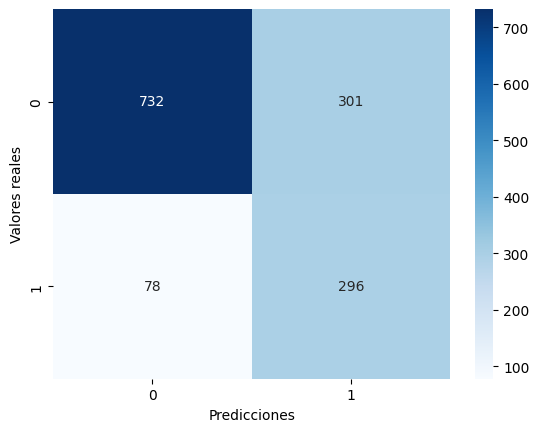

In [67]:
#verifico los resultados con la matriz de confusión
cm = confusion_matrix(y_test, y_pred_RL)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicciones')
plt.ylabel('Valores reales')
plt.show()

In [68]:
#verifico resultados con las métricas
print(classification_report(y_test, y_pred_RL))

              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.75      1407



**Análisis Mediante Curva ROC**

In [69]:
y_proba_RL = modelo_RL.predict_proba(X_test_scaled)[:, 1]
fpr_RL, tpr_RL, thresholds = roc_curve(y_test, y_proba_RL)
auc_val_RL = roc_auc_score(y_test, y_proba_RL)
print(f"AUC validación: {auc_val_RL:.3f}")

AUC validación: 0.832


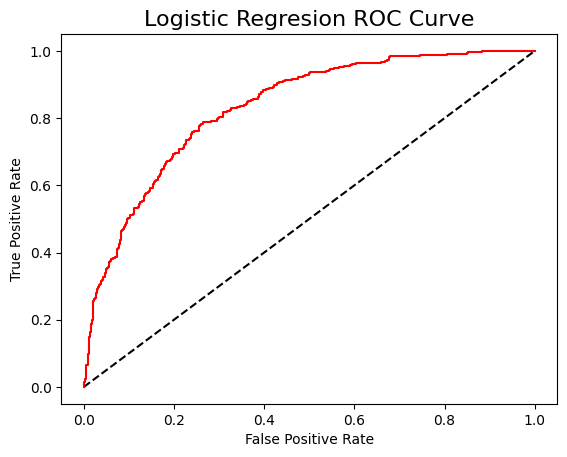

In [70]:
plt.plot([0, 1], [0, 1], 'k--' )
plt.plot(fpr_RL, tpr_RL, label='REGRESION LOGÍSTICA',color = "r")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regresion ROC Curve',fontsize=16)
plt.show();

In [71]:
# Determino el umbral más óptimo mediante el Método de Youden
youden_index = tpr_RL - fpr_RL
best_threshold = thresholds[np.argmax(youden_index)]
print(f"Umbral óptimo (Youden): {best_threshold:.3f}")

# Evaluo con ese nuevo umbral
y_pred_optimo_RL = (y_proba_RL >= best_threshold).astype(int)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_optimo_RL))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_optimo_RL, digits=3))

Umbral óptimo (Youden): 0.525

Matriz de confusión:
[[761 272]
 [ 79 295]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0      0.906     0.737     0.813      1033
           1      0.520     0.789     0.627       374

    accuracy                          0.751      1407
   macro avg      0.713     0.763     0.720      1407
weighted avg      0.803     0.751     0.763      1407



### **Modelo Random Forest**

In [54]:
modelo_RF = RandomForestClassifier(random_state=42)

In [60]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [6, 8, 10, 12],
    'min_samples_split': [ 2, 4, 5],
    'min_samples_leaf': [1, 2],
    }
grid = GridSearchCV(
    estimator=modelo_RF,
    param_grid= param_grid,
    scoring='recall' ,
    cv=5)

grid.fit(X_train, y_train)

# Muestra los mejores parámetros encontrados
print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor puntuación:", grid.best_score_)

Mejores hiperparámetros: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Mejor puntuación: 0.791304347826087


In [61]:
#pruebo el modelo
modelo_RF = RandomForestClassifier(random_state=42, max_depth=6, min_samples_leaf=1, min_samples_split=2, n_estimators=200, class_weight='balanced')
modelo_RF.fit(X_train, y_train)
y_pred_RF = modelo_RF.predict(X_test)

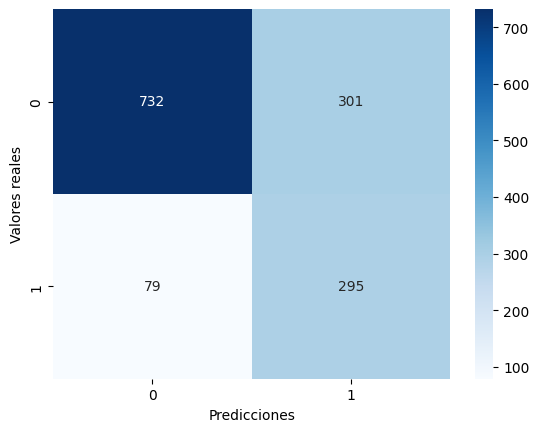

In [62]:
#verifico los resultados con la matriz de confusión
cm = confusion_matrix(y_test, y_pred_RF)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicciones')
plt.ylabel('Valores reales')
plt.show()

In [63]:
#verifico resultados con las métricas
print(classification_report(y_test, y_pred_RF))

              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



**Análisis mediante Curva ROC**

AUC validación: 0.833


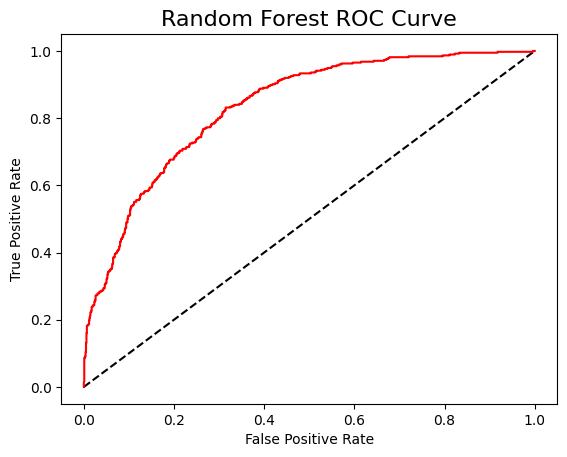

In [64]:
y_proba = modelo_RF.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_val = roc_auc_score(y_test, y_proba)
print(f"AUC validación: {auc_val:.3f}")

plt.plot([0, 1], [0, 1], 'k--' )
plt.plot(fpr, tpr, label='Random Forest',color = "r")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve',fontsize=16)
plt.show();

In [65]:
# Aplico el Método de Youden para encontrar el mejor Umbral
youden_index = tpr - fpr
best_threshold = thresholds[np.argmax(youden_index)]
print(f"Umbral óptimo (Youden): {best_threshold:.3f}")

# Evaluo con ese nuevo umbral
y_pred_optimo = (y_proba >= best_threshold).astype(int)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_optimo))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_optimo, digits=3))

Umbral óptimo (Youden): 0.467

Matriz de confusión:
[[708 325]
 [ 63 311]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0      0.918     0.685     0.785      1033
           1      0.489     0.832     0.616       374

    accuracy                          0.724      1407
   macro avg      0.704     0.758     0.700      1407
weighted avg      0.804     0.724     0.740      1407



#### **Conclusión Final**

Se aplicaron los modelos de Regresión Logistica y Bosque Aleatorio. Se aplicaron técnicas de optimización de hiperparámetros y selección del umbral mas adecuado. Estas técnicas se las aplicó con enfoque en obtener el mejor rendimiento en la sensibilidad del modelo (Recall). Esto debido a que la idea es que el modelo pueda identificar lo mejor posible a los clientes que vayan a desertar para que la empresa pueda aplicar estrategias de retención adecuadas.